# Taiwan's Export Boom Through a Supply Chain Lens

**Author:** Pham Hong Hieu (Haven) · **Data:** official monthly statistics from Taiwan's Ministry of Finance and Taiwan
International Ports Corporation, January 2001 to September 2026

## Why this analysis

In the first nine months of 2026, Taiwan's exports rose 46% on a year earlier, after a 30% rise in 2025. Headlines report
the value. A supply chain planner needs different answers:

1. **What is growing?** Is this broad growth, or one product group?
2. **Where is it going?** How has the customer map changed, and how exposed is the country to a single lane?
3. **Is it volume or price?** More goods need more capacity. Higher prices do not.
4. **Do the ports see it?** If value rises, do container volumes follow?
5. **What does the boom depend on?** Where are the upstream dependencies, and do imports give early warning?

The project is self-initiated. All data come directly from government open data sources, and there are no sample or
course datasets involved.

## 1. Setup

The notebook analyses a fixed snapshot ending in September 2026, so its numbers stay reproducible when the raw files are
refreshed. The interactive dashboard always uses the latest month.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sys.path.insert(0, str(Path("../src").resolve()))
from taiwan_trade import data as d
from taiwan_trade import metrics as m

SNAPSHOT_END = pd.Timestamp("2026-09-01")
YEAR, LAST_MONTH = SNAPSHOT_END.year, SNAPSHOT_END.month
BASE_YEAR = 2021  # the last year before the recent surge, and the base year of the official indices
MACHINERY = d.SECTIONS[d.ELECTRONICS]

FIG_DIR, TABLE_DIR = Path("../reports/figures"), Path("../reports/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

INK, BLUE, TEAL, AMBER, RED, GREY = "#1F2937", "#1D4E89", "#087F8C", "#E5A12B", "#C8374D", "#9AA5B1"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 13, "figure.dpi": 110, "axes.edgecolor": "#C9D1D9",
                     "grid.color": "#E6EBEF", "text.color": INK, "axes.labelcolor": INK})
pd.set_option("display.float_format", lambda x: f"{x:,.1f}", "display.width", 180)


def snapshot(frame):
    return frame[frame.index <= SNAPSHOT_END]


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def billions(axis):
    axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v / 1e3:,.0f}B"))

In [2]:
trade = snapshot(d.load_trade_total())
hs = d.load_trade_by_hs()
exports_hs = snapshot(hs[hs["flow"] == "exports"].pivot(index="month", columns="section", values="value"))
imports_hs = snapshot(hs[hs["flow"] == "imports"].pivot(index="month", columns="section", values="value"))
goods = snapshot(d.load_major_goods())
countries_x, countries_m = snapshot(d.load_countries("exports")), snapshot(d.load_countries("imports"))
markets_x = {k: snapshot(d.load_market_sections("x", k)) for k in d.MARKETS}
markets_m = {k: snapshot(d.load_market_sections("m", k)) for k in d.MARKETS}
indices = snapshot(d.load_indices())
ports, all_ports = d.load_ports()
ports, all_ports = ports[ports["month"] <= SNAPSHOT_END], snapshot(all_ports)
teu = all_ports["total"]

print(f"Trade data: {trade.index.min():%b %Y} to {trade.index.max():%b %Y} ({len(trade)} months)")
print(f"Price and volume indices: from {indices.index.min():%b %Y}")
print(f"Port data: from {teu.index.min():%b %Y}")

Trade data: Jan 2001 to Sep 2026 (309 months)
Price and volume indices: from Jan 2011
Port data: from Jan 2001


## 2. Data quality

The sources use Republic of China years (115 = 2026), mix Big5 and UTF-8, include annual subtotal rows, and format
numbers inconsistently. `src/taiwan_trade/data.py` normalises all of this and `tests/` verifies the result.

Do the published parts add up to the published totals? This decides which denominator is safe to use.

In [3]:
checks = {}
for label, parts, total in [
    ("Exports by HS section", exports_hs, trade["exports"]),
    ("Imports by HS section", imports_hs, trade["imports"]),
    ("Exports by country", countries_x, trade["exports"]),
    ("Imports by country", countries_m, trade["imports"]),
]:
    gap = m.reconciliation_gap(parts, total)
    in_year = m.same_months(gap, YEAR, LAST_MONTH)
    in_base = m.same_months(gap, BASE_YEAR, LAST_MONTH)
    checks[label] = {
        f"unallocated Jan-{SNAPSHOT_END:%b} {BASE_YEAR} (%)": in_base["gap"].sum() / m.same_months(total.to_frame(), BASE_YEAR, LAST_MONTH).sum().iloc[0] * 100,
        f"unallocated Jan-{SNAPSHOT_END:%b} {YEAR} (%)": in_year["gap"].sum() / m.same_months(total.to_frame(), YEAR, LAST_MONTH).sum().iloc[0] * 100,
        f"unallocated Jan-{SNAPSHOT_END:%b} {YEAR} ($M)": in_year["gap"].sum(),
    }
quality = pd.DataFrame(checks).T
quality.to_csv(TABLE_DIR / "data_reconciliation.csv", index_label="check")

# Where does the unallocated import value sit? Compare the Asia subtotal with its listed countries.
raw_imports = d._monthly(d.read_csv("country_imports"), d.parse_gregorian_period) / 1_000
raw_imports.columns = [c.replace("(千元)", "").strip() for c in raw_imports.columns]
columns = list(raw_imports.columns)
asia_members = columns[columns.index("亞洲") + 1:columns.index("中東")]
asia_gap = m.same_months(snapshot(raw_imports["亞洲"] - raw_imports[asia_members].sum(axis=1)).to_frame("gap"), YEAR, LAST_MONTH)["gap"].sum()
print(f"Unallocated imports inside the Asia subtotal, Jan-Sep {YEAR}: ${asia_gap:,.0f}M")
quality

Unallocated imports inside the Asia subtotal, Jan-Sep 2026: $60,860M


,unallocated Jan-Sep 2021 (%),unallocated Jan-Sep 2026 (%),unallocated Jan-Sep 2026 ($M)
Exports by HS section,0.5,0.2,"1,242.3"
Imports by HS section,1.1,1.0,"5,072.1"
Exports by country,0.5,0.4,"2,471.7"
Imports by country,4.1,12.2,"61,006.3"


Three of the four tables reconcile closely. **Imports by country do not.** About 12% of 2026 imports are in the published
total but in no listed country, up from about 4% in 2021. Almost all of the gap sits inside the Asia subtotal, and the
source does not explain it. Two rules follow:

- All shares are calculated against the **published total**, never against the sum of listed countries. Otherwise the
  shares would be inflated.
- Import shares by country are therefore lower bounds, and they are presented with this caveat.

## 3. What is growing?

Each comparison uses January to September of both years, because 2026 is incomplete.

In [4]:
def jan_sep(frame, year):
    return m.same_months(frame, year, LAST_MONTH)


headline = pd.DataFrame({y: jan_sep(trade, y)[["exports", "imports", "balance"]].sum() for y in [BASE_YEAR, 2024, 2025, YEAR]}).T
headline["exports_yoy_pct"] = headline["exports"].pct_change() * 100
headline.loc[BASE_YEAR, "exports_yoy_pct"] = np.nan
machinery_by_year = pd.Series({y: jan_sep(exports_hs, y)[MACHINERY].sum() for y in range(2011, YEAR + 1)})
rest_by_year = pd.Series({y: jan_sep(exports_hs, y).drop(columns=MACHINERY).sum().sum() for y in range(2011, YEAR + 1)})
growth = jan_sep(exports_hs, YEAR).sum() - jan_sep(exports_hs, BASE_YEAR).sum()
machinery_contribution = growth[MACHINERY] / growth.sum() * 100

print(f"Exports, Jan-Sep {YEAR}: ${headline.loc[YEAR, 'exports'] / 1e3:,.1f}B, {headline.loc[YEAR, 'exports_yoy_pct']:+.1f}% on {YEAR - 1}")
print(f"Machinery & electrical share of the export increase since {BASE_YEAR}: {machinery_contribution:.0f}%")
print(f"All other exports: ${rest_by_year[BASE_YEAR] / 1e3:,.1f}B in {BASE_YEAR} -> ${rest_by_year[YEAR] / 1e3:,.1f}B in {YEAR} ({rest_by_year[YEAR] / rest_by_year[BASE_YEAR] * 100 - 100:+.1f}%)")
headline

Exports, Jan-Sep 2026: $661.5B, +46.2% on 2025
Machinery & electrical share of the export increase since 2021: 106%
All other exports: $122.1B in 2021 -> $101.4B in 2026 (-16.9%)


,exports,imports,balance,exports_yoy_pct
2021,"324,000.3","277,081.7","46,918.6",NaN
2024,"349,022.6","289,575.1","59,447.5",7.7
2025,"452,573.3","354,555.9","98,017.4",29.7
2026,"661,533.2","500,871.0","160,662.2",46.2


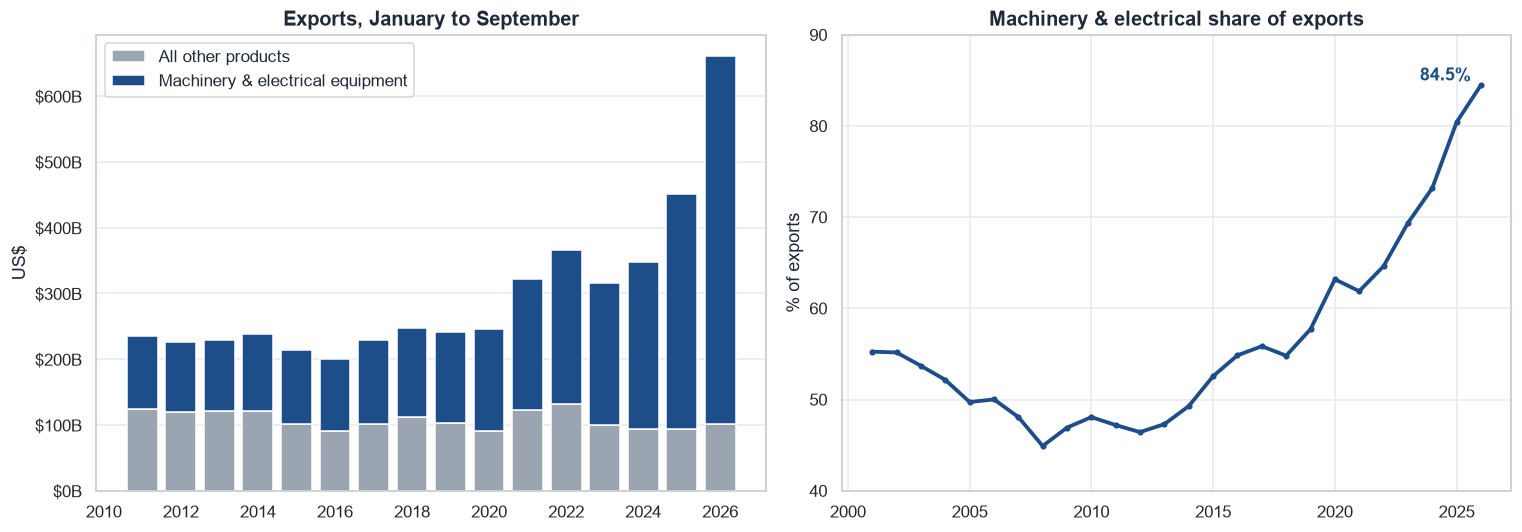

,machinery_share_pct,product_hhi
month,,
2001,55.2,"3,320.6"
2010,48.1,"2,647.8"
2021,61.9,"4,016.6"
2023,69.4,"4,927.5"
2025,80.4,"6,514.7"
2026,84.5,"7,169.3"


In [5]:
yearly_x = exports_hs.groupby(exports_hs.index.year).sum()
partial = yearly_x.index == YEAR
concentration = pd.DataFrame({
    "machinery_share_pct": yearly_x[MACHINERY] / trade["exports"].groupby(trade.index.year).sum() * 100,
    "product_hhi": [m.hhi(row, total=trade.loc[str(y), "exports"].sum()) for y, row in yearly_x.iterrows()],
})
concentration.round(1).to_csv(TABLE_DIR / "product_concentration.csv", index_label="year")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
years = machinery_by_year.index
axes[0].bar(years, rest_by_year, color=GREY, label="All other products")
axes[0].bar(years, machinery_by_year, bottom=rest_by_year, color=BLUE, label="Machinery & electrical equipment")
axes[0].set(title="Exports, January to September", ylabel="US$")
billions(axes[0].yaxis)
axes[0].legend(loc="upper left")
axes[0].grid(axis="x", visible=False)

axes[1].plot(concentration.index, concentration["machinery_share_pct"], color=BLUE, linewidth=2.5, marker="o", markersize=3)
axes[1].set(title="Machinery & electrical share of exports", ylabel="% of exports", ylim=(40, 90))
axes[1].annotate(f"{concentration['machinery_share_pct'].iloc[-1]:.1f}%", (YEAR, concentration["machinery_share_pct"].iloc[-1]),
                 xytext=(-40, 3), textcoords="offset points", fontweight="bold", color=BLUE)
fig.tight_layout()
save(fig, "01_what_is_growing")
plt.show()
concentration.loc[[2001, 2010, BASE_YEAR, 2023, 2025, YEAR]].round(1)

This is not a broad-based boom. **Machinery and electrical equipment accounts for more than 100% of the increase since
2021**, because everything else combined shrank by 17%. The product HHI rose from about 4,000 to about 7,200, where
2,500 is a common rule of thumb for "highly concentrated".

Inside the machinery group, the composition changed as well.

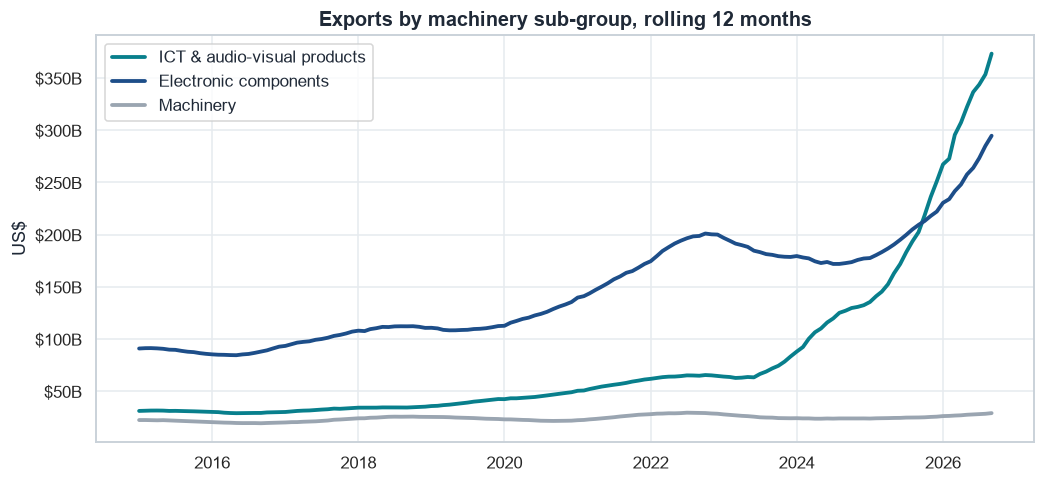

ICT & audio-visual has led electronic components on a rolling 12-month basis since Oct 2025


,Electronic components,Machinery,ICT & audio-visual products
2021,"125,221.0","20,303.0","43,939.0"
2024,"126,714.0","17,880.0","98,759.0"
2025,"158,917.0","18,805.0","168,751.0"
2026,"231,539.0","22,203.0","291,006.0"


In [6]:
goods_compare = pd.DataFrame({y: jan_sep(goods, y).sum() for y in [BASE_YEAR, 2024, 2025, YEAR]}).T
goods_compare.to_csv(TABLE_DIR / "machinery_subgroups.csv", index_label="year")

rolling_goods = goods.rolling(12).sum().dropna().loc["2015":]
fig, ax = plt.subplots(figsize=(11, 4.8))
for column, colour in [("ICT & audio-visual products", TEAL), ("Electronic components", BLUE), ("Machinery", GREY)]:
    ax.plot(rolling_goods.index, rolling_goods[column], color=colour, linewidth=2.5, label=column)
ax.set(title="Exports by machinery sub-group, rolling 12 months", ylabel="US$")
billions(ax.yaxis)
ax.legend(loc="upper left")
save(fig, "02_machinery_subgroups")
plt.show()

crossover_ict = m.first_lasting_crossover(goods["ICT & audio-visual products"], goods["Electronic components"])
print(f"ICT & audio-visual has led electronic components on a rolling 12-month basis since {crossover_ict:%b %Y}")
goods_compare.round(0)

ICT and audio-visual products overtook electronic components, the historical core of Taiwan's export model, and grew
more than sixfold from 2021. The official category does not isolate servers or AI hardware, so this analysis can say
that finished ICT equipment is driving the shift, but cannot attribute it to a specific product from these data.

## 4. Where is it going?

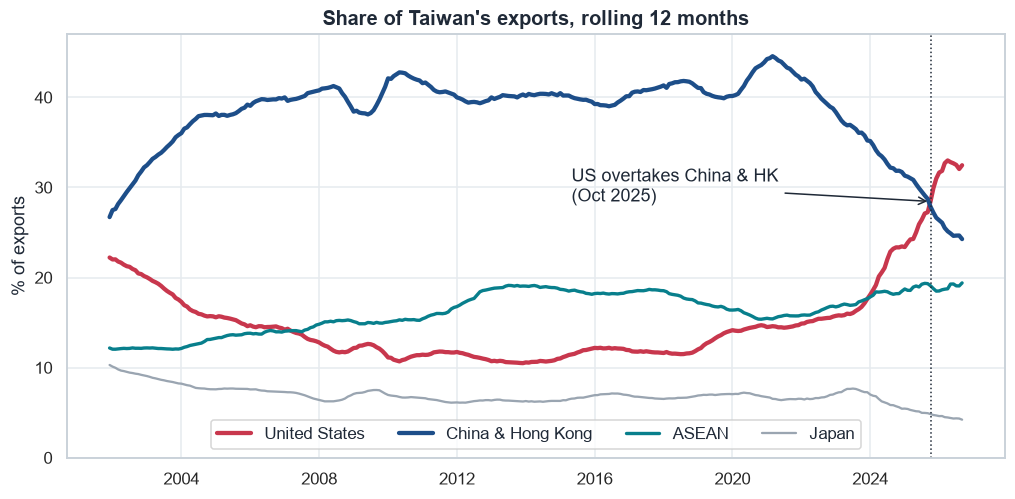

,share_2021_pct,share_2026_pct,machinery_in_basket_2021_pct,machinery_in_basket_2026_pct
China & Hong Kong,42.7,24.2,71.9,85.4
United States,14.5,31.4,55.4,91.6
ASEAN,15.9,20.2,59.5,84.7
Japan,6.6,4.2,61.6,70.0
South Korea,4.5,4.0,74.1,85.8
Germany,1.8,1.0,52.2,66.6


In [7]:
total_x = trade["exports"]
market_share = pd.DataFrame({
    d.MARKETS[k]: frame["total"].rolling(12).sum() / total_x.rolling(12).sum() * 100 for k, frame in markets_x.items()
}).dropna()
market_share.round(1).to_csv(TABLE_DIR / "market_share_rolling12.csv", index_label="month")

crossover = m.first_lasting_crossover(markets_x["usa"]["total"], markets_x["china_hk"]["total"])

fig, ax = plt.subplots(figsize=(11, 5))
styles = {"United States": (RED, 2.8), "China & Hong Kong": (BLUE, 2.8), "ASEAN": (TEAL, 2.2), "Japan": (GREY, 1.5)}
for name, (colour, width) in styles.items():
    ax.plot(market_share.index, market_share[name], color=colour, linewidth=width, label=name)
ax.axvline(crossover, color=INK, linestyle=":", linewidth=1)
ax.annotate(f"US overtakes China & HK\n({crossover:%b %Y})", (crossover, market_share.loc[crossover, "United States"]),
            xytext=(-235, 0), textcoords="offset points", arrowprops=dict(arrowstyle="->", color=INK))
ax.set(title="Share of Taiwan's exports, rolling 12 months", ylabel="% of exports", ylim=(0, 47))
ax.legend(loc="lower center", ncol=4)
save(fig, "03_market_shift")
plt.show()

market_table = pd.DataFrame({
    d.MARKETS[k]: {
        f"share_{BASE_YEAR}_pct": jan_sep(f, BASE_YEAR)["total"].sum() / jan_sep(total_x.to_frame(), BASE_YEAR).sum().iloc[0] * 100,
        f"share_{YEAR}_pct": jan_sep(f, YEAR)["total"].sum() / jan_sep(total_x.to_frame(), YEAR).sum().iloc[0] * 100,
        f"machinery_in_basket_{BASE_YEAR}_pct": jan_sep(f, BASE_YEAR)[MACHINERY].sum() / jan_sep(f, BASE_YEAR)["total"].sum() * 100,
        f"machinery_in_basket_{YEAR}_pct": jan_sep(f, YEAR)[MACHINERY].sum() / jan_sep(f, YEAR)["total"].sum() * 100,
    } for k, f in markets_x.items()
}).T
market_table.to_csv(TABLE_DIR / "market_summary.csv", index_label="market")
market_table

In [8]:
def country_hhi(frame, total, year):
    return m.hhi(jan_sep(frame, year).sum(), total=jan_sep(total.to_frame(), year).sum().iloc[0])


hhi_table = pd.DataFrame({
    y: {"product HHI (HS sections)": m.hhi(jan_sep(exports_hs, y).sum(), total=jan_sep(total_x.to_frame(), y).sum().iloc[0]),
        "market HHI (countries)": country_hhi(countries_x, total_x, y)}
    for y in [2011, 2016, BASE_YEAR, 2024, 2025, YEAR]
}).T
hhi_table.to_csv(TABLE_DIR / "concentration_comparison.csv", index_label="year")
hhi_table.round(0)

,product HHI (HS sections),market HHI (countries)
2011,"2,563.0","1,191.0"
2016,"3,219.0","1,139.0"
2021,"4,012.0","1,357.0"
2024,"5,374.0","1,261.0"
2025,"6,309.0","1,378.0"
2026,"7,169.0","1,452.0"


Two different kinds of concentration are moving in different directions:

- **The market map rotated more than it concentrated.** The US share more than doubled and China & Hong Kong lost about
  18 points, but the market HHI rose only about 7%, from about 1,360 to about 1,450. The largest customer changed, but
  the country is not much more dependent on a small set of customers.
- **The product map collapsed into one group.** Every market now buys mostly machinery and electronics. The share inside
  the US basket jumped from 55% to 92%.

So market diversification gives less protection than it appears, because the same product cycle runs through every market.

## 5. Volume or price?

The official chain indices (2021 = 100) separate value into quantity and unit value. This matters because volume consumes
production and logistics capacity, while price does not.

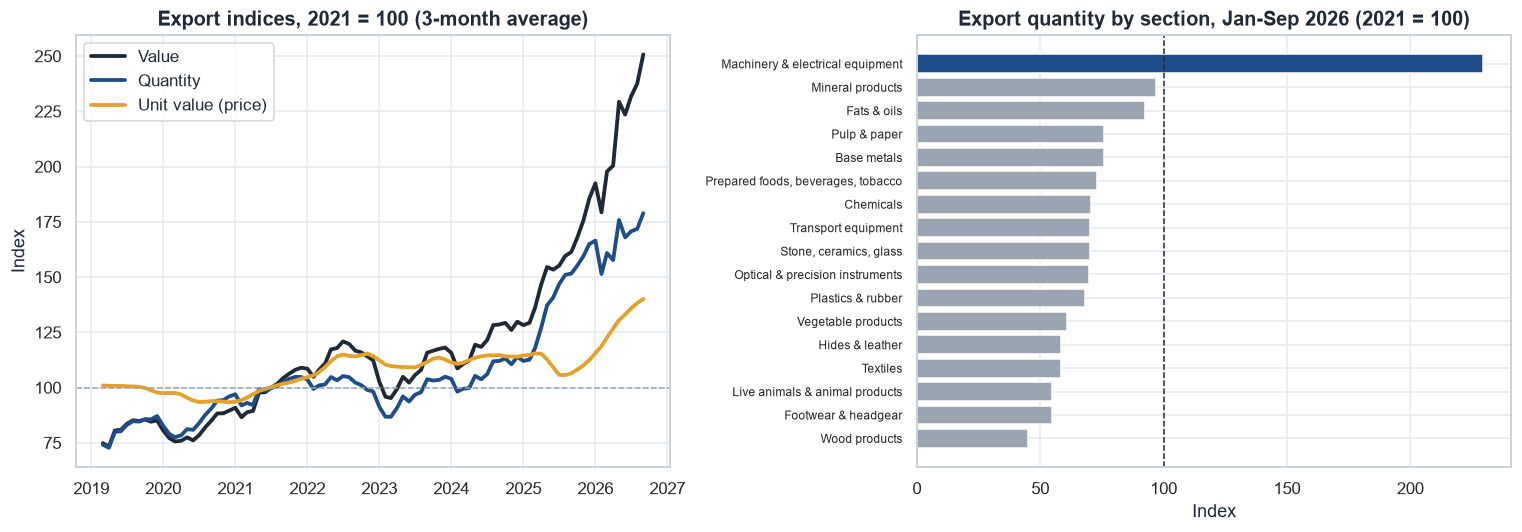

Volume explains about 65% of the rise in export value since 2021 (log decomposition)
Sections with export quantity below the 2021 level: 16 of 17


,multiple_2021_to_2026
Export value,2.31
Export quantity,1.73
Export unit value (price),1.33
Machinery quantity,2.35
Machinery unit value (price),1.34


In [9]:
multiples = pd.Series({
    "Export value": m.growth_multiple(indices["export_value"], BASE_YEAR, YEAR, LAST_MONTH),
    "Export quantity": m.growth_multiple(indices["export_quantity"], BASE_YEAR, YEAR, LAST_MONTH),
    "Export unit value (price)": m.growth_multiple(indices["export_unit_value"], BASE_YEAR, YEAR, LAST_MONTH),
    "Machinery quantity": m.growth_multiple(indices["machinery_quantity"], BASE_YEAR, YEAR, LAST_MONTH),
    "Machinery unit value (price)": m.growth_multiple(indices["machinery_unit_value"], BASE_YEAR, YEAR, LAST_MONTH),
}, name=f"multiple_{BASE_YEAR}_to_{YEAR}")
log_share_volume = np.log(multiples["Export quantity"]) / np.log(multiples["Export value"]) * 100

by_section = jan_sep(snapshot(d.load_quantity_by_section()), YEAR).mean()
below_base = (by_section < 100).sum()
by_section.round(1).rename("quantity_index").to_csv(TABLE_DIR / "quantity_by_section.csv", index_label="section")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
idx = indices.loc["2019":].rolling(3).mean().dropna()
axes[0].plot(idx.index, idx["export_value"], color=INK, linewidth=2.5, label="Value")
axes[0].plot(idx.index, idx["export_quantity"], color=BLUE, linewidth=2.5, label="Quantity")
axes[0].plot(idx.index, idx["export_unit_value"], color=AMBER, linewidth=2.5, label="Unit value (price)")
axes[0].axhline(100, color=GREY, linewidth=1, linestyle="--")
axes[0].set(title="Export indices, 2021 = 100 (3-month average)", ylabel="Index")
axes[0].legend(loc="upper left")

ordered = by_section.sort_values()
axes[1].barh(ordered.index, ordered.values, color=[BLUE if v > 100 else GREY for v in ordered.values])
axes[1].axvline(100, color=INK, linestyle="--", linewidth=1)
axes[1].tick_params(axis="y", labelsize=8)
axes[1].set(title=f"Export quantity by section, Jan-Sep {YEAR} (2021 = 100)", xlabel="Index")
fig.tight_layout()
save(fig, "04_volume_or_price")
plt.show()

print(f"Volume explains about {log_share_volume:.0f}% of the rise in export value since {BASE_YEAR} (log decomposition)")
print(f"Sections with export quantity below the 2021 level: {below_base} of {len(by_section)}")
multiples.round(2).to_frame().to_csv(TABLE_DIR / "volume_price_multiples.csv", index_label="measure")
multiples.map("{:.2f}".format).to_frame()

Both matter, but they tell different stories. Value multiplied by about 2.3, made up of about **1.7× quantity** and about
**1.3× price**, so volume explains roughly two thirds of the rise. Most of the price effect is recent: the 2026 price
index jumped from about 110 to about 132.

The right-hand chart is the more striking one. Machinery quantity has more than doubled, while **every other section in the
index ships less than it did in 2021**, most of them by 20% or more. Many traditional exporters have less volume to move, and that
matters for ports.

## 6. Do the ports see it?

In [10]:
density = m.value_density(trade["trade"], teu)
density["usd_per_teu"].round(0).tail(10).to_frame().T

month,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
usd_per_teu,"38,405.0","40,387.0","40,188.0","43,257.0","53,597.0","61,769.0","57,664.0","62,388.0","83,055.0","115,298.0"


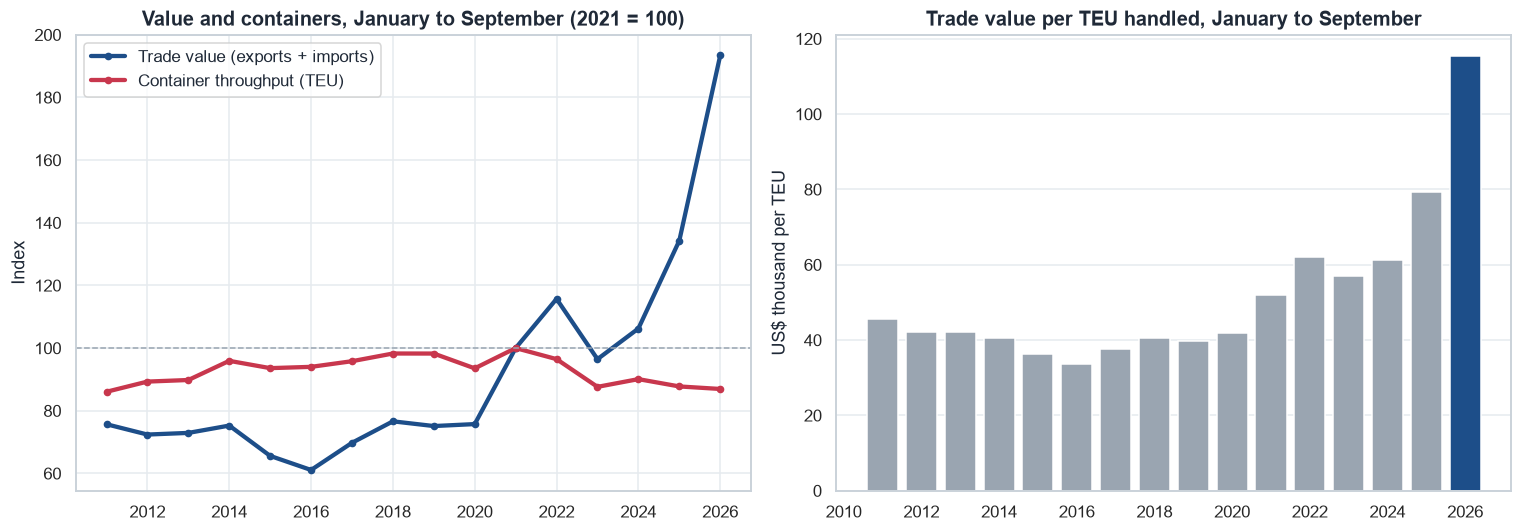

TEU, Jan-Sep: 11,595,010 in 2021 -> 10,081,748 in 2026 (-13.1%)
Trade value, Jan-Sep: 1.93x
Value per TEU: $51,840 -> $115,298 (2.22x)


In [11]:
teu_jan_sep = pd.Series({y: jan_sep(all_ports, y)["total"].sum() for y in range(2011, YEAR + 1)})
value_jan_sep = pd.Series({y: jan_sep(trade, y)["trade"].sum() for y in range(2011, YEAR + 1)})
rebased = pd.DataFrame({"Trade value": value_jan_sep / value_jan_sep[BASE_YEAR] * 100,
                        "Container throughput (TEU)": teu_jan_sep / teu_jan_sep[BASE_YEAR] * 100})
density_jan_sep = value_jan_sep * 1e6 / teu_jan_sep

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(rebased.index, rebased["Trade value"], color=BLUE, linewidth=2.8, marker="o", markersize=4, label="Trade value (exports + imports)")
axes[0].plot(rebased.index, rebased["Container throughput (TEU)"], color=RED, linewidth=2.8, marker="o", markersize=4, label="Container throughput (TEU)")
axes[0].axhline(100, color=GREY, linewidth=1, linestyle="--")
axes[0].set(title=f"Value and containers, January to September ({BASE_YEAR} = 100)", ylabel="Index")
axes[0].legend(loc="upper left")
axes[1].bar(density_jan_sep.index, density_jan_sep.values / 1e3, color=[GREY] * (len(density_jan_sep) - 1) + [BLUE])
axes[1].set(title="Trade value per TEU handled, January to September", ylabel="US$ thousand per TEU")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "05_value_vs_containers")
plt.show()

print(f"TEU, Jan-Sep: {teu_jan_sep[BASE_YEAR]:,.0f} in {BASE_YEAR} -> {teu_jan_sep[YEAR]:,.0f} in {YEAR} ({teu_jan_sep[YEAR] / teu_jan_sep[BASE_YEAR] * 100 - 100:+.1f}%)")
print(f"Trade value, Jan-Sep: {value_jan_sep[YEAR] / value_jan_sep[BASE_YEAR]:.2f}x")
print(f"Value per TEU: ${density_jan_sep[BASE_YEAR]:,.0f} -> ${density_jan_sep[YEAR]:,.0f} ({density_jan_sep[YEAR] / density_jan_sep[BASE_YEAR]:.2f}x)")
pd.DataFrame({"teu": teu_jan_sep, "trade_usd_m": value_jan_sep, "usd_per_teu": density_jan_sep}).round(0).to_csv(TABLE_DIR / "value_vs_containers.csv", index_label="year")

Trade value almost doubled since 2021, while containers **fell by 13%**. Value per TEU went from about $52,000 to about
$115,000. This measure divides all trade by sea containers, so it does not describe what is inside a box; it shows how far
the value of trade has separated from the country's container volume.

Which part of trade do containers actually follow? If ports follow traditional goods rather than electronics, TEU growth
should track non-machinery exports.

In [12]:
series = {"Machinery exports": exports_hs[MACHINERY],
          "All other exports": exports_hs.drop(columns=MACHINERY).sum(axis=1),
          "All other imports": imports_hs.drop(columns=MACHINERY).sum(axis=1),
          "Machinery imports": imports_hs[MACHINERY]}
coupling_table = pd.concat({
    "2012-2019": m.coupling(teu, series, "2012", "2019")["correlation"],
    "2020-2026": m.coupling(teu, series, "2020", None)["correlation"],
}, axis=1)
coupling_table.round(2).to_csv(TABLE_DIR / "teu_coupling.csv", index_label="series")
coupling_table.map("{:.2f}".format)

,2012-2019,2020-2026
Machinery exports,0.38,0.36
All other exports,0.45,0.78
All other imports,0.49,0.65
Machinery imports,0.15,0.49


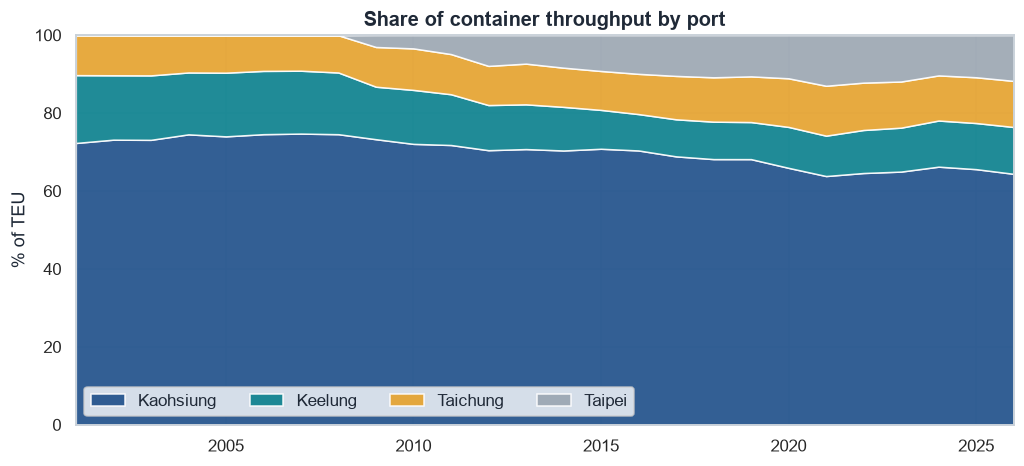

port,Kaohsiung,Keelung,Taichung,Taipei
month,,,,
2001,72.3,17.4,10.3,0.0
2010,72.1,13.8,10.7,3.4
2021,63.8,10.4,12.8,13.0
2026,64.4,12.0,11.8,11.7


In [13]:
share_by_port = ports.pivot_table(index=ports["month"].dt.year, columns="port", values="total", aggfunc="sum")
main_ports = ["Kaohsiung", "Keelung", "Taichung", "Taipei"]
share_by_port = share_by_port.div(share_by_port.sum(axis=1), axis=0)[main_ports] * 100
share_by_port.round(1).to_csv(TABLE_DIR / "port_share.csv", index_label="year")

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.stackplot(share_by_port.index, share_by_port.T.values, labels=main_ports, colors=[BLUE, TEAL, AMBER, GREY], alpha=0.9)
ax.set(title="Share of container throughput by port", ylabel="% of TEU", ylim=(0, 100), xlim=(share_by_port.index.min(), share_by_port.index.max()))
ax.legend(loc="lower left", ncol=4, frameon=True)
save(fig, "06_port_share")
plt.show()
share_by_port.loc[[2001, 2010, BASE_YEAR, YEAR]].round(1)

**Containers follow the traditional economy.** Since 2020, year-on-year TEU growth has correlated about 0.78 with non-machinery
exports and only about 0.36 with machinery exports. In 2012-2019 the two were much closer (0.45 and 0.38). This fits the earlier result: the
products that fill containers are the ones losing volume, while the products creating the value leave little trace at the
ports. It is a correlation over a limited period, so it supports this explanation without proving it.

Kaohsiung remains dominant, although it has held about 64% since 2021 after falling from 72% in 2001, mainly to the new Taipei
port. Throughput is below its 2021 peak, so the boom is not creating overall container volume pressure in these data.

**What these data cannot confirm.** High-value electronics commonly move by air, so a shift to air freight is a natural
explanation for value leaving the container numbers. The only official monthly airport cargo file available as open data
stops in 2022, so this remains a **hypothesis to test**, not a finding.

## 7. What does the boom depend on?

Machinery share of all imports: 46.8% -> 65.5%


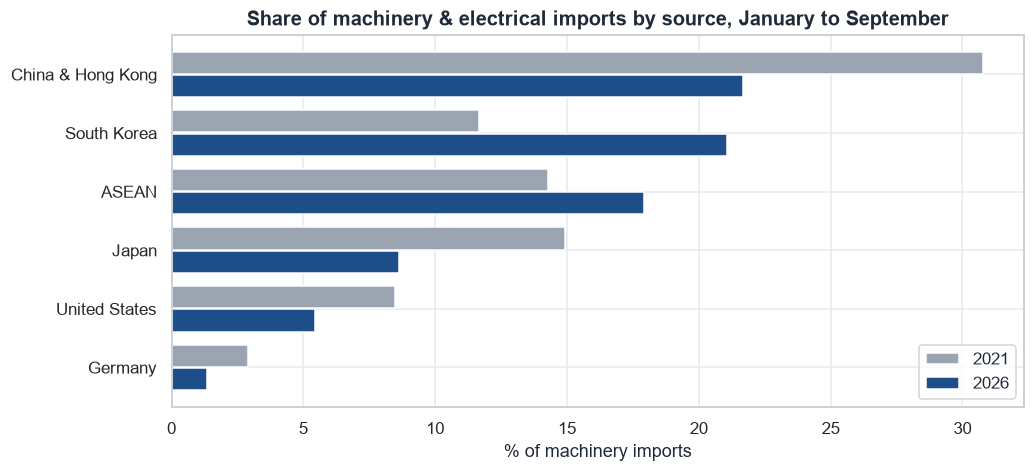

,share_of_machinery_imports_2021_pct,share_of_machinery_imports_2026_pct,machinery_imports_2026_usd_m
China & Hong Kong,30.8,21.7,"71,147.0"
South Korea,11.6,21.1,"69,175.3"
ASEAN,14.3,17.9,"58,788.2"
Japan,14.9,8.6,"28,258.4"
United States,8.5,5.4,"17,882.4"
Germany,2.9,1.4,"4,452.8"


In [14]:
import_table = pd.DataFrame({
    d.MARKETS[k]: {
        f"share_of_machinery_imports_{BASE_YEAR}_pct": jan_sep(f, BASE_YEAR)[MACHINERY].sum() / jan_sep(imports_hs, BASE_YEAR)[MACHINERY].sum() * 100,
        f"share_of_machinery_imports_{YEAR}_pct": jan_sep(f, YEAR)[MACHINERY].sum() / jan_sep(imports_hs, YEAR)[MACHINERY].sum() * 100,
        f"machinery_imports_{YEAR}_usd_m": jan_sep(f, YEAR)[MACHINERY].sum(),
    } for k, f in markets_m.items()
}).T.sort_values(f"share_of_machinery_imports_{YEAR}_pct", ascending=False)
import_table.to_csv(TABLE_DIR / "machinery_import_sources.csv", index_label="source")

machinery_share_imports = {y: jan_sep(imports_hs, y)[MACHINERY].sum() / jan_sep(trade, y)["imports"].sum() * 100 for y in [BASE_YEAR, YEAR]}
print(f"Machinery share of all imports: {machinery_share_imports[BASE_YEAR]:.1f}% -> {machinery_share_imports[YEAR]:.1f}%")

fig, ax = plt.subplots(figsize=(10, 4.4))
positions = np.arange(len(import_table))
ax.barh(positions - 0.2, import_table[f"share_of_machinery_imports_{BASE_YEAR}_pct"], height=0.38, color=GREY, label=str(BASE_YEAR))
ax.barh(positions + 0.2, import_table[f"share_of_machinery_imports_{YEAR}_pct"], height=0.38, color=BLUE, label=str(YEAR))
ax.set_yticks(positions, import_table.index)
ax.invert_yaxis()
ax.set(title="Share of machinery & electrical imports by source, January to September", xlabel="% of machinery imports")
ax.legend()
save(fig, "07_upstream_sources")
plt.show()
import_table.round(1)

The upstream map has moved as well. South Korea almost doubled its share of machinery imports, drawing level with China &
Hong Kong, whose share fell by about nine points. The six listed sources cover about 76% of machinery imports, and the rest
is not itemised in this dataset.

Machinery imports could also act as an early-warning signal, since components arrive before finished goods ship. The test
compares export growth with import growth up to six months earlier.

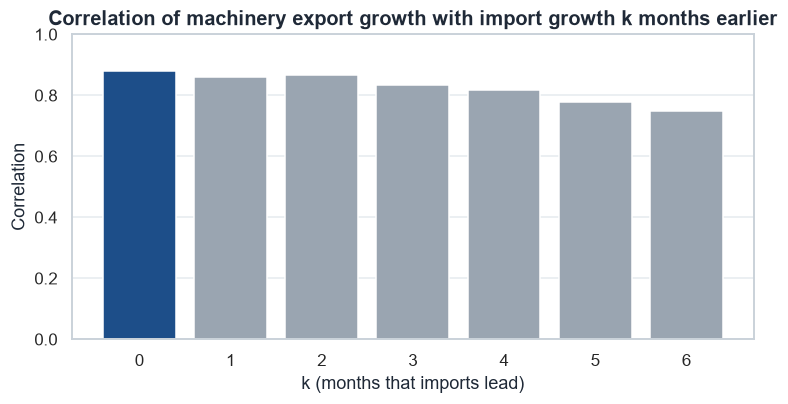

,0,1,2,3,4,5,6
correlation,0.88,0.86,0.87,0.84,0.82,0.78,0.75


In [15]:
lags = m.lead_lag(imports_hs[MACHINERY], exports_hs[MACHINERY])
lags.round(3).to_frame().to_csv(TABLE_DIR / "imports_lead_exports.csv", index_label="months_imports_lead")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(lags.index, lags.values, color=[BLUE if i == lags.idxmax() else GREY for i in lags.index])
ax.set(title="Correlation of machinery export growth with import growth k months earlier", xlabel="k (months that imports lead)", ylabel="Correlation", ylim=(0, 1))
ax.grid(axis="x", visible=False)
save(fig, "08_lead_lag")
plt.show()
lags.map("{:.2f}".format).to_frame().T

**No early warning here.** The correlation is highest at zero lag and generally falls as the lead increases. Machinery imports
and exports move together at this monthly level, so imports describe the same cycle at the same time and do not forecast it.
A more specific input series might still lead, but aggregate imports do not.

## 8. How exposed is the boom? A stress test

This sizes exposure by asking what a fall in one lane would remove from total exports, holding everything else constant. It
is deliberately simple: **it is an exposure measure, not a forecast**, and ignores diversion to other markets and the
matching fall in imports.

In [16]:
total_year = jan_sep(trade, YEAR)["exports"].sum()
lanes = {f"{d.MARKETS[k]}: machinery & electrical": jan_sep(f, YEAR)[MACHINERY].sum() for k, f in markets_x.items()}
lanes["All markets: machinery & electrical"] = jan_sep(exports_hs, YEAR)[MACHINERY].sum()
stress = m.stress_test(lanes, total_year)
stress.round(1).to_csv(TABLE_DIR / "stress_test.csv", index=False)

display(stress[["lane", "exports_usd_m", "share_of_exports_pct", "export_loss_at_10pct_fall_pct", "export_loss_at_20pct_fall_pct", "export_loss_at_30pct_fall_pct"]].round(1))

previous = {y: jan_sep(exports_hs, y)[MACHINERY].sum() for y in [2022, 2023]}
rest_prev = {y: rest_by_year[y] for y in [2022, 2023]}
print(f"Reference: in the 2023 downturn (Jan-Sep), machinery exports changed {previous[2023] / previous[2022] * 100 - 100:+.1f}% and all other exports {rest_prev[2023] / rest_prev[2022] * 100 - 100:+.1f}%")

,lane,exports_usd_m,share_of_exports_pct,export_loss_at_10pct_fall_pct,export_loss_at_20pct_fall_pct,export_loss_at_30pct_fall_pct
0,All markets: machinery & electrical,"558,917.7",84.5,8.4,16.9,25.3
1,United States: machinery & electrical,"190,393.0",28.8,2.9,5.8,8.6
2,China & Hong Kong: machinery & electrical,"136,698.3",20.7,2.1,4.1,6.2
3,ASEAN: machinery & electrical,"113,432.3",17.1,1.7,3.4,5.1
4,South Korea: machinery & electrical,"22,788.6",3.4,0.3,0.7,1.0
5,Japan: machinery & electrical,"19,435.5",2.9,0.3,0.6,0.9
6,Germany: machinery & electrical,"4,520.4",0.7,0.1,0.1,0.2


Reference: in the 2023 downturn (Jan-Sep), machinery exports changed -7.8% and all other exports -24.4%


One lane, **machinery to the United States, now represents nearly 29% of all Taiwanese exports**. A 20% fall in that lane alone
would remove nearly 6% of total exports. Machinery to China & Hong Kong and to ASEAN make up about 21% and 17%. For scale,
machinery exports fell about 8% in the 2023 downturn. All other exports fell about 24%, and they are still below their 2022
level.

## 9. What this means for supply chain decisions

| Finding | Decision it informs |
|---|---|
| Growth is one product group; other exports are 17% below 2021 | Do not read headline exports as demand for your sector. Plan non-electronics capacity on sector volumes |
| Value and containers have separated | Use TEU and quantity indices, not trade value, for ocean capacity and port planning |
| Every other indexed section ships less than in 2021 | Traditional exporters and the carriers serving them face soft volumes despite record trade |
| US machinery is about 29% of exports | Electronics supply chains need scenario plans for this lane: tariffs, demand and logistics disruption |
| South Korea's share of machinery imports almost doubled | Review supplier concentration in electronic inputs |
| Aggregate imports do not lead exports | Do not use total machinery imports as an early-warning indicator |

## 10. Limitations

- **Value and quantity, not weight.** Quantity indices are value-weighted indices of volume change. They are not tonnes.
- **Value per TEU mixes modes.** Trade value includes air freight while TEU counts only sea containers. It shows separation, and
  does not measure container contents.
- **No current air cargo data.** The open Taoyuan monthly file ends in 2022, so the air-freight explanation is untested.
- **Unallocated imports.** About 12% of 2026 imports have no listed country, so country import shares are lower bounds.
- **Broad categories.** HS sections and the official sub-groups cannot isolate servers, chips or specific supply chains.
- **Correlation only.** The coupling and lead-lag results describe co-movement over a limited period and do not prove cause.
- **Partial year and revisions.** 2026 covers January to September, and recent official figures may be revised.